## Check the consistency between our measurmeents with desi-clustering

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import lsstypes as types

os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

sys.path.insert(0, '../../')
from cat_tools import get_measurement_fn, get_measurement_ready_fn
from fit_tools import read_data_from_fn
from helper import GET_REDSHIFT_SET, SNAP_TO_ZP

%load_ext autoreload
%autoreload 2

In [2]:
corr = 'mesh2'
version ='Abacus-v2'
tracer = 'QSO'
zsnaps, zranges = GET_REDSHIFT_SET(version, 'altmtl')
zrange = zranges[tracer[:3]][0]
zlabel = f'z{zrange[0]}-{zrange[1]}'
region = 'GCcomb'
for id in range(5):
    if tracer =='ELG': tracer = 'ELG_LOPnotqso'
    fn1 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/{tracer[:3]}/mock{id}/mpspk/mesh2_spectrum_poles_{tracer[:3]}_{zlabel}_DR2_v2.0.h5'
    fn2 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/abacus-hf-dr2-v2-altmtl/mock{id}/mesh2_spectrum_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    # fn1 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/data_splits/holi-v3-altmtl/mock{id}/mesh2_spectrum_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    # fn2 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/holi-v3-altmtl/mock{id}/mesh2_spectrum_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    # fn3 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/test/full_shape/base/abacus-hf-dr2-v2-altmtl/mock{id}/mesh2_spectrum_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    # fn2 = '/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/QSO/mock0/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_DR2_v2.0+dv_verr_nonparam.h5'
    # fn3 = '/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/QSO/mock0/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_DR2_v2.0+dv_verr_nonparam_zevol.h5'
    # fn4 = '/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/QSO/mock0/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_DR2_v2.0+dv_test.h5'
    fn_best_fit_alphas = ['/global/cfs/cdirs/desi/users/akrolew/C3PO/data/spec_z_dat/Abacus_lightcones/pkxi_dat/Pk_Abacus_QSO_jaxpower_v1.6.txt', 'Best-fit alpha_c and alplha_s']
    fn_fix_vel_bias_0 = ['/global/cfs/cdirs/desi/users/akrolew/C3PO/data/spec_z_dat/Abacus_lightcones/pkxi_dat/Pk_Abacus_QSO_jaxpower_v1.7.txt', 'alpha_c = 0, alpha_s = 1']
    fn_bound_vel_bias = ['/global/cfs/cdirs/desi/users/akrolew/C3PO/data/spec_z_dat/Abacus_lightcones/pkxi_dat/Pk_Abacus_QSO_jaxpower_v1.8.txt', 'alpha_c < 0.3, alpha_s < 1.3']

    lss = ['-', ':', '-.', '--', '--', ':', '-.', '-']
    fig = plt.figure(figsize=(6,4))
    if not os.path.exists(fn2) or not os.path.exists(fn1):
        continue
    for f, (fn, label) in enumerate([fn1, fn2, fn3, fn4]):
        (k, pk), _ = read_data_from_fn(fn, corr)
        plt.plot(k, k*pk[0], color = f'C{f}', ls =lss[f])
        plt.plot(k, k*pk[1], color = f'C{f}', ls =lss[f])
    plt.show()


NameError: name 'fn3' is not defined

<Figure size 600x400 with 0 Axes>

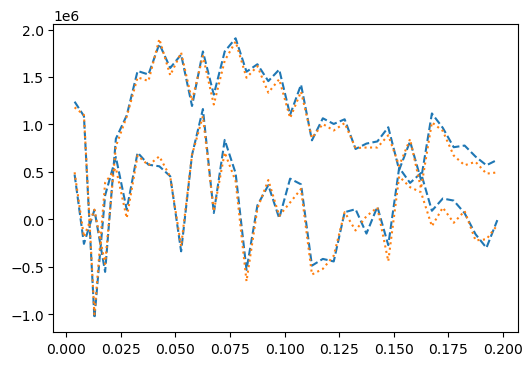

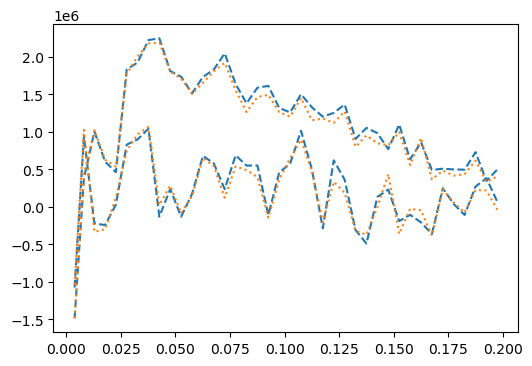

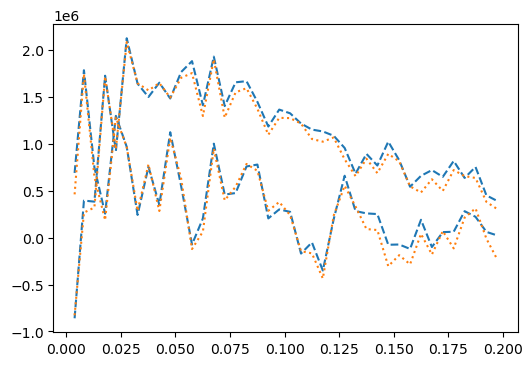

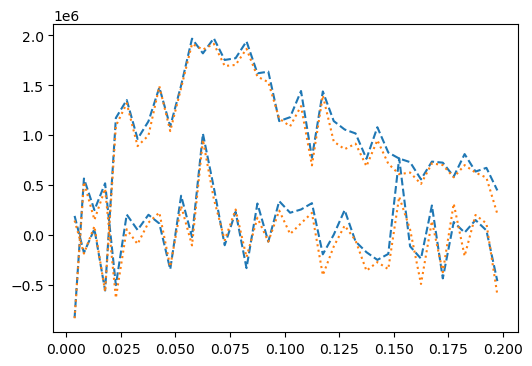

In [5]:
corr = 'mesh3_sugiyama'
version ='AbacusHF-v2'
# version ='holi-v3'
tracer = 'QSO' 
zsnaps, zranges = GET_REDSHIFT_SET(version, 'altmtl')
zrange = zranges[tracer[:3]][0]
zlabel = f'z{zrange[0]}-{zrange[1]}'
region = 'SGC'
lss = ['--', ':', '-.']
for id in range(4):
    if tracer =='ELG': tracer = 'ELG_LOPnotqso'
    fn1 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/{tracer[:3]}/mock{id}/mpspk/mesh3_spectrum_poles_sugiyama_{tracer[:3]}_{zlabel}_DR2_v2.0.h5'
    fn2 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/{tracer[:3]}/mock{id}/mpspk/mesh3_spectrum_poles_sugiyama_{tracer[:3]}_{zlabel}_DR2_v2.0+dv_verr_nonparam.h5'

    # fn2 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/{tracer[:3]}/mock{id}/mpspk/mesh3_spectrum_poles_sugiyama_{tracer[:3]}_{zlabel}_DR2_v2.0.h5'
    # fn1 = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/{version}/altmtl/{tracer[:3]}/mock{id}/mpspk/mesh3_spectrum_poles_sugiyama_{tracer[:3]}_{zlabel}_{region}_holi_v3.h5'
    # fn3 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/abacus-hf-dr2-v2-altmtl/mock{id}/mesh3_spectrum_sugiyama-diagonal_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    # fn3 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/holi-v3-altmtl/mock{id}/mesh3_spectrum_sugiyama-diagonal_poles_{tracer}_{zlabel}_{region}_weight-default-FKP.h5'
    fig = plt.figure(figsize=(6,4))
    for f, fn in enumerate([fn1, fn2][:]):
        (k, bk), _ = read_data_from_fn(fn, corr)
        # if fn == fn1: 
            # bk[(0,0,0)]=bk[(0,0,0)]*1.71
            # bk[(2,0,2)]=bk[(2,0,2)]*1.71
        plt.plot(k, k**2*bk[(0,0,0)], color = f'C{f}', ls = lss[f], label=f'mock{id} {tracer} z{zrange[0]}-{zrange[1]} B000')
        plt.plot(k, k**2*bk[(2,0,2)], color = f'C{f}', ls = lss[f], label=f'mock{id} {tracer} z{zrange[0]}-{zrange[1]} B202')
    # plt.legend()
    plt.show()

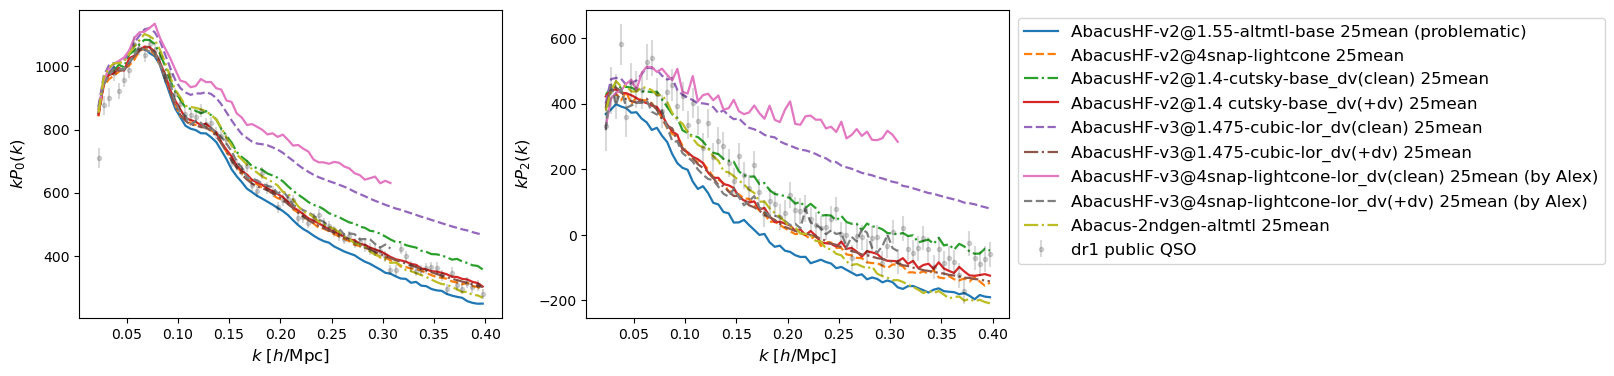

In [35]:
from unittest import result

BASE_DIR = '/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base'
MOCK_DIR = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3'

fn_abacus_2nd = [f'{BASE_DIR}/abacus-2ndgen-dr2-altmtl/mock{{mock_id}}/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'Abacus-2ndgen-altmtl 25mean']
fn_hf_v2_base_altmtl_old = [f'{BASE_DIR}/abacus-hf-dr2-v2-altmtl/mock{{mock_id}}/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'AbacusHF-v2@1.55-altmtl-base 25mean (problematic)']

# fn_base_uchuu = [f'{BASE_DIR}/uchuu-hf-altmtl/mock{{mock_id}}/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'Uchuu-hf mean']
# fn_base_holi = [f'{BASE_DIR}/holi-v3-altmtl/mock{{mock_id}}/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'holi-v3-altmtl 50mean']
# fn_base_glum = [f'{BASE_DIR}/glam-uchuu-v2-altmtl/mock{{mock_id}}/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'glam-uchuu-altmtl 50mean']

fn_hf_v2_base_lightcone = [f'{MOCK_DIR}/AbacusHF-4snap/lightcone/QSO/AbacusSummit_base_c000_ph0{{mock_id}}/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_hf_4snap_base.h5', 'AbacusHF-v2@4snap-lightcone 25mean']

fn_hf_v2_base_cutsky = [f'{MOCK_DIR}/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph0{{mock_id}}/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_hf_v2.0_base.h5', 'AbacusHF-v2@1.4-cutsky-base 25mean']
fn_hf_v2_base_dv_cutsky_clean = [f'{MOCK_DIR}/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph0{{mock_id}}/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_hf_v2.0_base_dv.h5', 'AbacusHF-v2@1.4-cutsky-base_dv(clean) 25mean']
fn_hf_v2_base_dv_cutsky_dv = [f'{MOCK_DIR}/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph0{{mock_id}}/mpspk/mesh2_spectrum_poles_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam.h5', 'AbacusHF-v2@1.4 cutsky-base_dv(+dv) 25mean']

fn_hf_v2_mc_cubic = [f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/mock_challenge/abacushf_MC/v2/QSO/mesh2_spectrum_poles_QSO_z1.400_c000_hod-base_los-z_{{mock_id}}.h5', 'AbacusHF-v2@1.4 cubic 25mean']

fn_hf_v2_lor_cubic_clean = [f'/pscratch/sd/h/hanyuz/measurements_abacushf_MC/v2/QSO_lorentzian/mesh2_spectrum_poles_QSO_z1.475_c000_hod-base_lorentzian_dv_cat_fixed_los-z_novsmear_{{mock_id}}.h5', 'AbacusHF-v3@1.475-cubic-lor_dv(clean) 25mean']
fn_hf_v2_lor_cubic_dv = [f'/pscratch/sd/h/hanyuz/measurements_abacushf_MC/v2/QSO_lorentzian/mesh2_spectrum_poles_QSO_z1.475_c000_hod-base_lorentzian_dv_cat_fixed_los-z_{{mock_id}}.h5', 'AbacusHF-v3@1.475-cubic-lor_dv(+dv) 25mean']

fn_hf_v2_lor_lightcone_clean = [f'/dvs_ro/cfs/cdirs/desi/mocks/cai/abacus_HF_lightcones/DR2/Pk/QSO/v1.9/mesh2_spectrum_poles_LRG_z0.8-2.1_ph0{{mock_id}}.h5', 'AbacusHF-v3@4snap-lightcone-lor_dv(clean) 25mean (by Alex)']
fn_hf_v2_lor_lightcone_dv = [f'/dvs_ro/cfs/cdirs/desi/mocks/cai/abacus_HF_lightcones/DR2/Pk/QSO/v1.9dv/mesh2_spectrum_poles_LRG_z0.8-2.1_ph0{{mock_id}}.h5', 'AbacusHF-v3@4snap-lightcone-lor_dv(+dv) 25mean (by Alex)']

fn_dr1_v15 = [f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/base/data-dr1-v1.5/mesh2_spectrum_poles_QSO_z0.8-2.1_GCcomb_weight-default-FKP.h5', 'dr1 v1.5 QSO']
fn_public_dr1 = ['/global/cfs/cdirs/desi/public/dr1/vac/dr1/full-shape-bao-clustering/v1.0/data/spectrum/spectrum-poles_QSO_GCcomb_z0.8-2.1.h5', 'dr1 public QSO']
cov_fn_public_dr1 = '/global/cfs/cdirs/desi/public/dr1/vac/dr1/full-shape-bao-clustering/v1.0/data/covariance/EZmock/covariance_spectrum-poles_QSO_GCcomb_z0.8-2.1.h5'


# fns = [fn_base_AbacusHF, fn_base_abacus_2nd, fn_base_holi, fn_base_glum, fn_public_dr1]

fns = [fn_hf_v2_base_altmtl_old,
    fn_hf_v2_base_lightcone,
       fn_hf_v2_base_dv_cutsky_clean, fn_hf_v2_base_dv_cutsky_dv, 
       fn_hf_v2_lor_cubic_clean, fn_hf_v2_lor_cubic_dv, 
       fn_hf_v2_lor_lightcone_clean, fn_hf_v2_lor_lightcone_dv,
       fn_abacus_2nd, fn_public_dr1]

def read_mean_mesh2(fn_template, mock_ids):
    ks = []
    pks = []
    used = []
    for mock_id in mock_ids:
        fn = fn_template.format(mock_id=mock_id)
        if not os.path.exists(fn):
            # print(f'missing {fn}')
            continue
        (k, pk), _ = read_data_from_fn(fn, 'mesh2', bin_type='kmax0.4')
        ks.append(np.asarray(k))
        pks.append(np.asarray(pk))
        used.append(mock_id)
    if not pks:
        raise FileNotFoundError(f'No mock files found for {fn_template}')
    return ks[0], np.mean(pks, axis=0)

lss = ['-', '--', '-.', '-', '--', '-.', '-', '--', '-.', '-', '--', '-.']
fig = plt.figure(figsize=(12,4))
for ill in [0,1]:
    ax = fig.add_subplot(1,2,ill+1)
    for f, (fn, label) in enumerate(fns):
        if f != len(fns)-1:
            mock_ids = range(25)
        else:
            mock_ids = [1]
        if 'public' in label:
            data = types.read(fn)
            data = data.select(k=slice(0, None, 5)).select(k=(0.02, 0.4))
            k = data.get(ells=0).coords('k')
            Pk = [data.get(ells=ell).values()['value'] for ell in data.ells]
            cov=types.read(cov_fn_public_dr1)
            cov = cov.at.observable.match(data)
            err = np.asarray(cov.std())
            errs = np.split(err, 3)
            # ax.plot(k, k*Pk[ill], color=f'C{f}', label=label)
            ax.errorbar(k, k*Pk[ill], yerr=k*errs[ill], markersize=3, fmt='o', color=f'black', alpha=0.15, label=label)
        else:
            if fn.endswith('.h5'):
                (k, pk) = read_mean_mesh2(fn, mock_ids=mock_ids)
            else:
                k, p0, p2, p4 = np.loadtxt(fn, unpack=True)
                pk = [p0, p2, p4]
            ax.plot(k, k*pk[ill], color = f'C{f}', ls =lss[f], lw=1.6, label = label)
    if ill==0:
        ax.set_ylabel('$k P_0(k)$', fontsize=12)
        ax.set_xlabel('$k$ [$h$/Mpc]', fontsize=12)
    if ill==1:
        ax.set_ylabel('$k P_2(k)$', fontsize=12)
        ax.set_xlabel('$k$ [$h$/Mpc]', fontsize=12)
        ax.legend(bbox_to_anchor=(1.0, 1), loc='upper left', fontsize=12)
plt.show()

AbacusHF HOD version 
base: free velocity bias
base_dv: free velocity bias + fix redshift errrors empirically determined from repeats observations
lor_dv: no velocity bias + free Lorentizian profile errors + empirically catastrophic errors

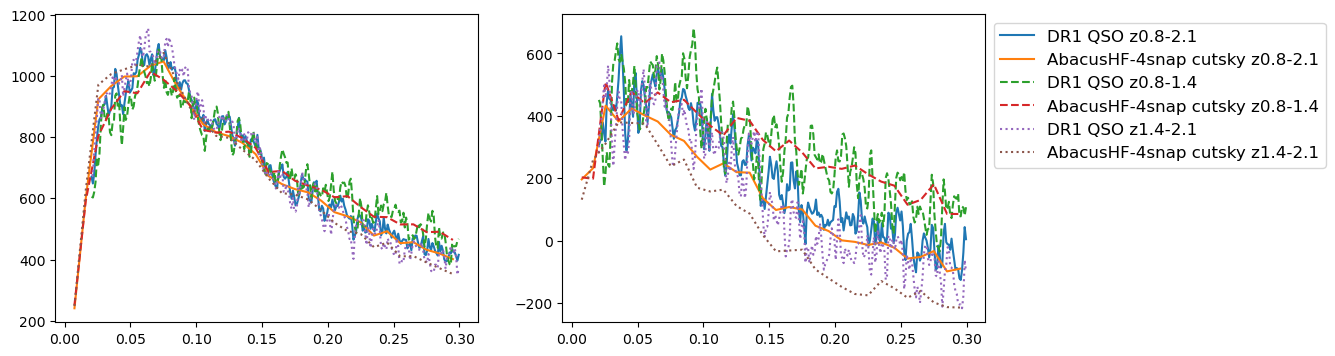

In [ ]:
data_path = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/data-dr1-v1.5/mpspk'

tracer = 'QSO'
zranges = dict(QSO = [(0.8, 2.1), (0.8, 1.4), (1.4, 2.1), (0.8, 1.1), (1.1, 1.4), (1.4, 1.7), (1.7, 2.1)][:3])
zsnaps = ['merged','0p950_1p250','1p550_1p850']
zsnap_labesl = ['z0.8-2.1', 'z0.8-1.4', 'z1.4-2.1']

lss = ['-', '--', ':', ':', '--', '-.', ':']
fig = plt.figure(figsize=(12,4))


cutsky_fn = '/pscratch/sd/x/xryang/share/pk_auto_0p950.dat'
data = np.loadtxt(cutsky_fn)

k = data[:, 3] 
pk0  = data[:, 5]
pk2  = data[:, 6]

for ill in [0,1]:
    ax = fig.add_subplot(1,2,ill+1)
    for indz, zsnap, zrange in zip(range(len(zsnaps)), zsnaps, zranges[tracer]):
        fn = f'{data_path}/mesh2_spectrum_poles_QSO_z{zrange[0]}-{zrange[1]}_GCcomb.h5'
        if not os.path.exists(fn):
            print(f'missing {fn}')
            continue
        (k, pk), _ = read_data_from_fn(fn, 'mesh2', bin_type='test')
        ax.plot(k, k*pk[ill], ls=lss[indz], label=f'DR1 QSO z{zrange[0]}-{zrange[1]}')
        fn_cut =  f'/pscratch/sd/x/xryang/share/pk_auto_{zsnap}.dat'
        print()
        data_cut = np.loadtxt(fn_cut)
        k_cut = data_cut[:, 3] 
        pk_cut = [data_cut[:, 5], data_cut[:, 6]]
        ax.plot(k_cut, k_cut*pk_cut[ill], ls=lss[indz], label=f'AbacusHF-4snap cutsky {zsnap_labesl[indz]}')
        if ill == 1:
            ax.legend(bbox_to_anchor=(1.0, 1), loc='upper left', fontsize=12)

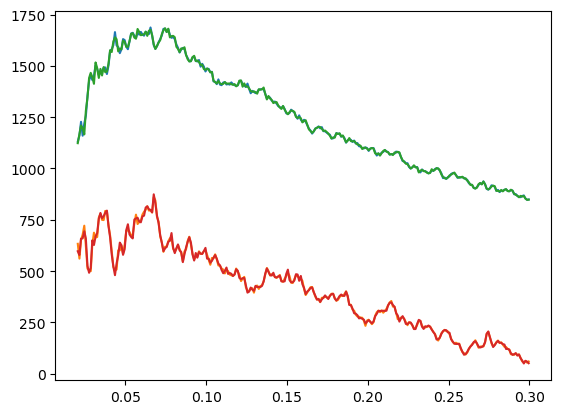

In [14]:
fn1 = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/LRG/mock18/mpspk/mesh2_spectrum_poles_LRG_z0.8-1.1_NGC_DR2_v2.0.h5'
fn2 = '/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/abacus-hf-dr2-v2-altmtl/mock18/mesh2_spectrum_poles_LRG_z0.8-1.1_NGC_weight-default-FKP.h5'

corr = 'mesh2'
for fn in [fn1, fn2]:
    (k, pk), _ = read_data_from_fn(fn, corr)
    plt.plot(k, k*pk[0], label=f'{fn}')
    plt.plot(k, k*pk[1], label=f'{fn}')

[000184.67]  06-11 01:25  fit_tools                    INFO     Read /global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/box/abacus-hf-v1/mesh2_spectrum_poles_QSO_z1.400_c000_hod-base_los-z_0.h5
[000184.68]  06-11 01:25  PowerSpectrumMultipoles      INFO     Loading /global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v1/boxes/QSO/z1.400/AbacusSummit_base_c000_ph000/mpspk/pkpoles_QSO_zp1.400_DR2_v1.0.npy.
[000184.70]  06-11 01:25  fit_tools                    INFO     Read /global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/box/abacus-hf-v1/mesh2_spectrum_poles_QSO_z1.400_c000_hod-base_los-z_1.h5
[000184.72]  06-11 01:25  PowerSpectrumMultipoles      INFO     Loading /global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v1/boxes/QSO/z1.400/AbacusSummit_base_c000_ph001/mpspk/pkpoles_QSO_zp1.400_DR2_v1.0.npy.


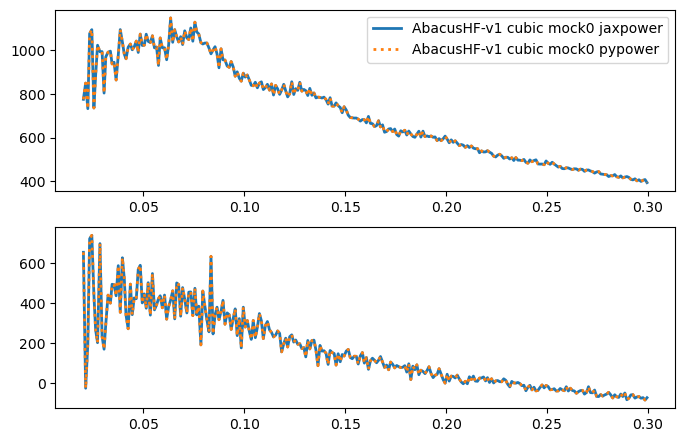

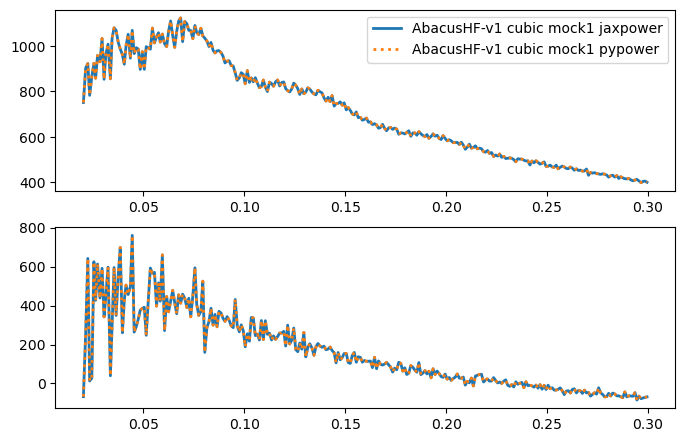

In [8]:
for mockid in range(2):
    fig = plt.figure(figsize=(8, 8))
    gs = gridspec.GridSpec(3, 1, wspace=0.05)
    mockid3 = f'{mockid:03d}'
    fn1 = f'/global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/box/abacus-hf-v1/mesh2_spectrum_poles_QSO_z1.400_c000_hod-base_los-z_{mockid}.h5'
    fn2 = f'/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v1/boxes/QSO/z1.400/AbacusSummit_base_c000_ph{mockid3}/mpspk/pkpoles_QSO_zp1.400_DR2_v1.0.npy'
    labels = [f'AbacusHF-v1 cubic mock{mockid} jaxpower', f'AbacusHF-v1 cubic mock{mockid} pypower']
    # fn3 = f'/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v1/boxes/QSO/sn1p400/AbacusSummit_base_c000_ph{mockid3}/mpspk/pkpoles_QSO_zp1.400_DR2_v1.0.npy'
    for fn in [fn1, fn2]:
        if fn == fn1:
            (k,pk), _ = read_data_from_fn(fn, 'mesh2', bin_type='test', verbose=True)
        else:
            (k,pk), _ = read_data_from_fn(fn, 'pk', bin_type='test')
        for ill in [0,1]:
            ax = plt.subplot(gs[ill])
            ax.plot(k, k*pk[ill], label=labels[[fn1, fn2].index(fn)] , ls='-' if fn == fn1 else ':', lw=2)
    ax = plt.subplot(gs[0])
    ax.legend()

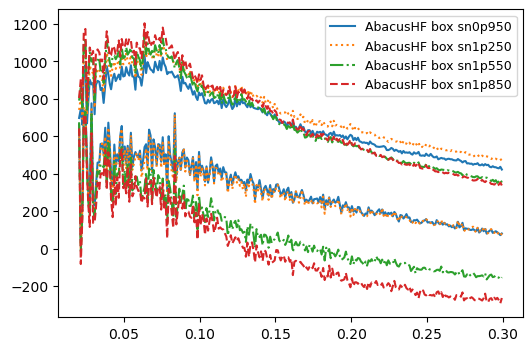

In [4]:
corr = 'mesh2'
version ='Abacus-v2'
tracer = 'QSO'
zsnaps, zranges = GET_REDSHIFT_SET(version, 'altmtl')
zrange = zranges[tracer[:3]][0]
zlabel = f'z{zrange[0]}-{zrange[1]}'

zsnaps = ['sn0p950', 'sn1p250', 'sn1p550', 'sn1p850']
mock_id = '000'

lss = ['-', ':', '-.', '--', '--', ':', '-.', '-']

fig = plt.figure(figsize=(6,4))
for indz, zsnap in enumerate(zsnaps):
    fn = f'/pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/Boxes/QSO/{zsnap}/AbacusSummit_base_c000_ph{mock_id}/mpspk/mesh2_spectrum_poles_QSO_{SNAP_TO_ZP(zsnap)}_DR2_v2.0.h5'
    (k, pk), _ = read_data_from_fn(fn, corr)
    plt.plot(k, k*pk[0], color = f'C{indz}', ls =lss[indz], label = f'AbacusHF box {zsnap}')
    plt.plot(k, k*pk[1], color = f'C{indz}', ls =lss[indz])
plt.legend(fontsize=9)
plt.show()

[000143.16]  06-11 01:24  fit_tools                    INFO     Read /global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/data-dr1-v1.5/mpspk/mesh2_spectrum_poles_QSO_z1.4-1.7ntile_0.h5
[000143.18]  06-11 01:24  fit_tools                    INFO     Read /global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/data-dr1-v1.5/mpspk/mesh2_spectrum_poles_QSO_z1.4-1.7ntile_1.h5


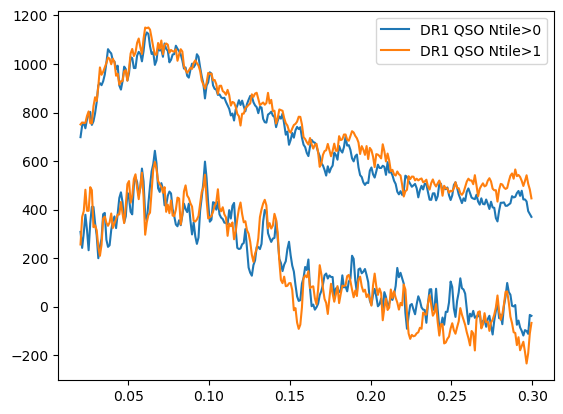

In [6]:
# from mockfactory import Catalog
# data = Catalog.read('/global/cfs/cdirs/desi/survey/catalogs/Y1/LSS/iron/LSScats/v1.5/QSO_clustering.dat.fits')
# print(len(data))
# data = data[(data['Z']>1.4) & (data['Z']<1.7)]
# print(len(data))

for id, tile in enumerate([0, 1,]):
    dir = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/data-dr1-v1.5/mpspk'
    fn = dir + f'/mesh2_spectrum_poles_QSO_z1.4-1.7ntile_{tile}.h5'
    (k, pk), _ = read_data_from_fn(fn, 'mesh2', bin_type='test', verbose=True)
    plt.plot(k, k*pk[0], label=f'DR1 QSO Ntile>{tile}', color=f'C{id}')
    plt.plot(k, k*pk[1], color=f'C{id}')
    plt.legend()

## Note:
### -- Small deviation may due to the meshzie difference

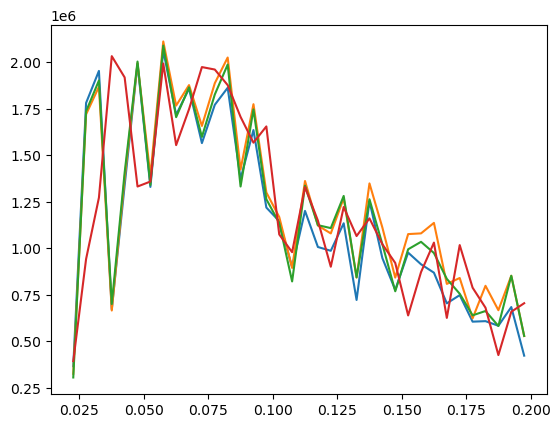

In [28]:
# fn = '//global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/data_splits/blinded_data/data-dr2-v2/'
dir = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph000/mpspk'
fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam.h5'
# fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam.h5'
(k, bk), _ = read_data_from_fn(fn, 'mesh3_sugiyama')
plt.plot(k, k**2*bk[0])
# plt.plot(k, k**2*bk[1])

fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv.h5'
(k, bk), _ = read_data_from_fn(fn, 'mesh3_sugiyama')
plt.plot(k, k**2*bk[0])
# plt.plot(k, k**2*bk[1])

fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam_zevol.h5'
(k, bk), _ = read_data_from_fn(fn, 'mesh3_sugiyama')
plt.plot(k, k**2*bk[0])
# plt.plot(k, k**2*bk[1])

dir = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph001/mpspk'
fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam.h5'
(k, bk), _ = read_data_from_fn(fn, 'mesh3_sugiyama')
plt.plot(k, k**2*bk[0])
# plt.plot(k, k**2*bk[1])

In [ ]:
# fn = '//global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/data_splits/blinded_data/data-dr2-v2/'
dir = '/global/cfs/cdirs/desi/users/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/cutsky/QSO/AbacusSummit_base_c000_ph000/mpspk'
fn = dir+'/mesh3_spectrum_poles_sugiyama_QSO_z0.8-2.1_hf_v2.0_base_dv+dv_verr_nonparam.h5'
(k, bk), _ = read_data_from_fn(fn, 'mesh3_sugiyama')
plt.plot(k, k**2*bk[0])
# plt.plot(k, k**2*bk[1])


In [11]:
bk[0]

array([1.35500112e+08, 5.49106222e+08, 4.50329404e+08, 1.10706217e+08,
       1.89256175e+08, 2.20124922e+08, 1.24036499e+08, 1.55128418e+08,
       1.08479375e+08, 1.01534203e+08, 7.67641066e+07, 7.65389618e+07,
       7.24390168e+07, 4.45699414e+07, 5.23541057e+07, 3.46439952e+07,
       2.55060135e+07, 1.77780290e+07, 2.59491099e+07, 1.97454645e+07,
       1.78538134e+07, 1.74682486e+07, 1.05189711e+07, 1.71119086e+07,
       1.33094772e+07, 8.37919735e+06, 1.10999057e+07, 9.52885426e+06,
       1.08941548e+07, 5.55770982e+06, 5.39412564e+06, 4.85831146e+06,
       4.79131184e+06, 4.85297541e+06, 5.03756098e+06, 2.70565655e+06])

In [110]:
## AI helps

import lsstypes as types

def _to_serializable(value):
    arr = np.asarray(value)
    if arr.ndim == 0:
        return arr.item()
    return arr.tolist()

def summarize_mesh2(fn):
    result = types.read(fn)
    summary = {}
    for key in ['boxsize', 'boxcenter', 'meshsize', 'los', 'wsum_data', 'wsum_randoms', 'wsum_data1']:
        if key in result.attrs:
            summary[key] = _to_serializable(result.attrs[key])
    for ell in result.ells:
        pole = result.get(ells=ell)
        values = pole.values()
        summary[f'k_ell{ell}_first5'] = np.asarray(pole.coords('k'))[:5].tolist()
        for name in ['value', 'norm', 'num_shotnoise']:
            if name in values:
                summary[f'{name}_ell{ell}_first5'] = np.asarray(values[name]).ravel()[:5].tolist()
    return result, summary

version = 'AbacusHF-v2'
tracer = 'LRG'
region = 'NGC'
mock_id = 0
zsnaps, zranges = GET_REDSHIFT_SET(version, 'altmtl')
zrange = zranges[tracer][0]
zsnap = zsnaps[tracer][0]

data_args = dict(
    version=version,
    domain='altmtl',
    tracer=tracer,
    zrange=zrange,
    zsnap=zsnap,
    mock_id=mock_id,
    region=region,
    use_dv=False,
    use_jax=True,
)

our_base = get_measurement_fn(**data_args)
desk_base = get_measurement_ready_fn(**data_args)
our_fn = our_base.format('mesh2_spectrum_poles')
desk_fn = desk_base.format('mesh2_spectrum_poles')

print('our :', our_fn)
print('desk:', desk_fn)

our_result, our_summary = summarize_mesh2(our_fn)
desk_result, desk_summary = summarize_mesh2(desk_fn)

print('\nOur attrs / samples')
for key, value in our_summary.items():
    print(f'{key}: {value}')

print('\nDesk attrs / samples')
for key, value in desk_summary.items():
    print(f'{key}: {value}')

(k_our, pk_our), _ = read_data_from_fn(our_base, 'mesh2')
(k_desk, pk_desk), _ = read_data_from_fn(desk_base, 'mesh2')
print('\nRebinned comparison from read_data_from_fn')
print('len(k_our), len(k_desk):', len(k_our), len(k_desk))
print('max |k_our - k_desk|:', float(np.max(np.abs(k_our - k_desk))))
print('k_our first5 :', np.asarray(k_our)[:5].tolist())
print('k_desk first5:', np.asarray(k_desk)[:5].tolist())
print('P0 first5 diff:', (np.asarray(pk_our[0])[:5] - np.asarray(pk_desk[0])[:5]).tolist())
print('P2 first5 diff:', (np.asarray(pk_our[1])[:5] - np.asarray(pk_desk[1])[:5]).tolist())

our : /pscratch/sd/s/shengyu/galaxies/catalogs/Y3/AbacusHF-v2/altmtl/LRG/mock0/mpspk/mesh2_spectrum_poles_LRG_z0.4-0.6_NGC_DR2_v2.0.h5
desk: /global/cfs/cdirs/desi/science/cai/desi-clustering/dr2/summary_statistics/full_shape/base/abacus-hf-dr2-v2-altmtl/mock0/mesh2_spectrum_poles_LRG_z0.4-0.6_NGC_weight-default-FKP.h5

Our attrs / samples
boxsize: [5649.18161822941, 5649.18161822941, 5649.18161822941]
boxcenter: [-617.3689692792768, -85.67403638469239, 618.0316720069409]
meshsize: [1000, 1000, 1000]
los: firstpoint
wsum_data1: 127921.28305424727
k_ell0_first5: [0.0, 0.0015753859277560837, 0.0025633463219974268, 0.0034859036381689685, 0.0045162958190113865]
value_ell0_first5: [-3368.395734920377, -442.6050174240592, 4196.788197000769, 13277.11328539401, 26998.511564050725]
norm_ell0_first5: [8.444841357776568, 8.444841357776568, 8.444841357776568, 8.444841357776568, 8.444841357776568]
num_shotnoise_ell0_first5: [28445.567611613795, 28445.567611613795, 28445.567611613795, 28445.56761161